<a href="https://colab.research.google.com/github/ranispl/FSOI/blob/develop/FSOI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install matplotlib numpy


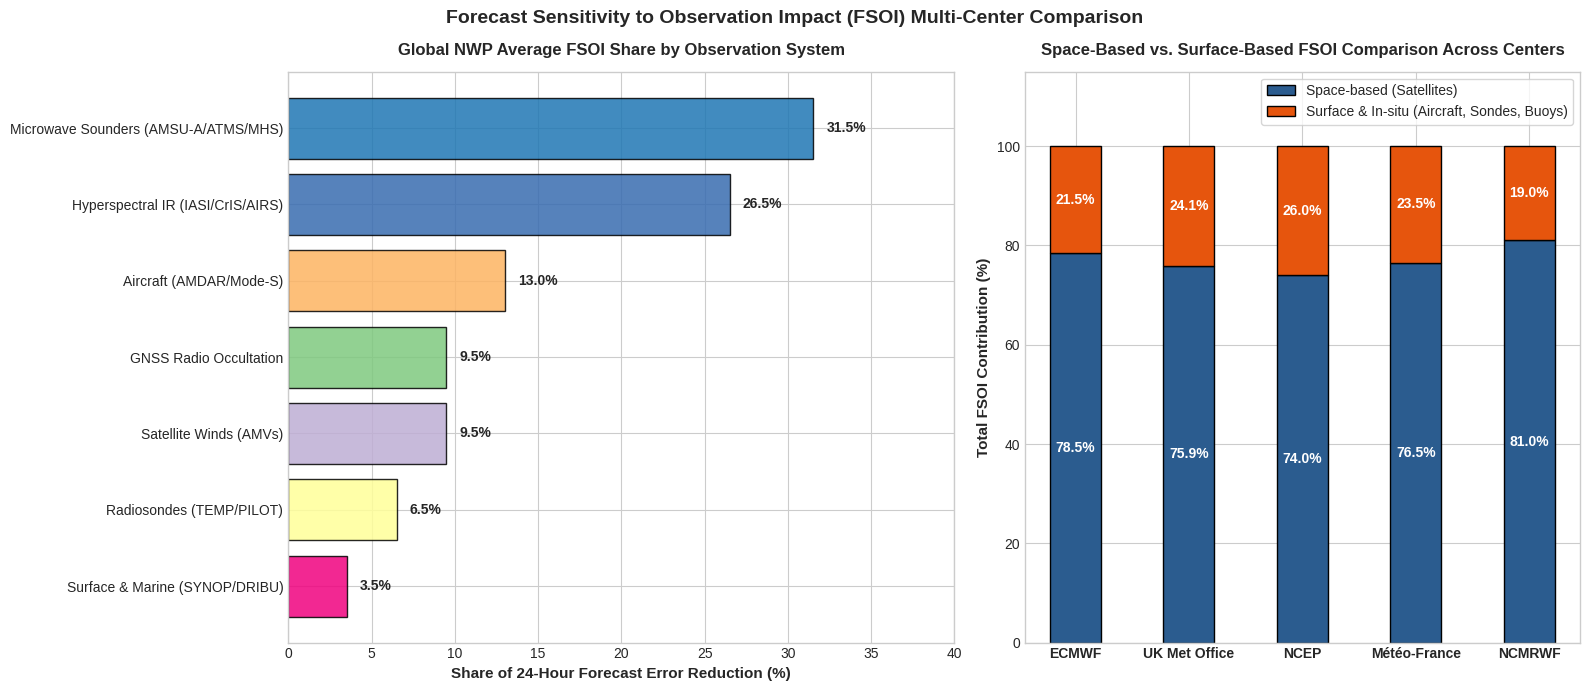

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Set publication style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.2, 1]})

# --- CHART 1: Average FSOI Share Across Global NWP Centers ---
categories = [
    'Microwave Sounders (AMSU-A/ATMS/MHS)',
    'Hyperspectral IR (IASI/CrIS/AIRS)',
    'Aircraft (AMDAR/Mode-S)',
    'GNSS Radio Occultation',
    'Satellite Winds (AMVs)',
    'Radiosondes (TEMP/PILOT)',
    'Surface & Marine (SYNOP/DRIBU)'
]

impact_shares = [31.5, 26.5, 13.0, 9.5, 9.5, 6.5, 3.5]
colors = ['#1f77b4', '#386cb0', '#fdb462', '#7fc97f', '#beaed4', '#ffff99', '#f0027f']

bars = ax1.barh(categories[::-1], impact_shares[::-1], color=colors[::-1], edgecolor='black', alpha=0.85)

ax1.set_xlabel('Share of 24-Hour Forecast Error Reduction (%)', fontsize=11, fontweight='bold')
ax1.set_title('Global NWP Average FSOI Share by Observation System', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlim(0, 40)

# Add data labels
for bar in bars:
    width = bar.get_width()
    ax1.text(width + 0.8, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', ha='left', va='center', fontsize=10, fontweight='bold')

# --- CHART 2: Satellite vs Surface-Based Contribution Across Centers ---
centers = ['ECMWF', 'UK Met Office', 'NCEP', 'Météo-France', 'NCMRWF']
satellite_impact = [78.5, 75.9, 74.0, 76.5, 81.0] # High satellite share over oceanic region for NCMRWF
surface_impact = [21.5, 24.1, 26.0, 23.5, 19.0]

x = np.arange(len(centers))
width = 0.45

p1 = ax2.bar(x, satellite_impact, width, label='Space-based (Satellites)', color='#2b5c8f', edgecolor='black')
p2 = ax2.bar(x, surface_impact, width, bottom=satellite_impact, label='Surface & In-situ (Aircraft, Sondes, Buoys)', color='#e6550d', edgecolor='black')

ax2.set_ylabel('Total FSOI Contribution (%)', fontsize=11, fontweight='bold')
ax2.set_title('Space-Based vs. Surface-Based FSOI Comparison Across Centers', fontsize=12, fontweight='bold', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(centers, fontsize=10, fontweight='bold')
ax2.set_ylim(0, 115)
ax2.legend(loc='upper right', frameon=True)

# Add percentage labels inside stacked bars
for i in range(len(centers)):
    ax2.text(i, satellite_impact[i]/2, f'{satellite_impact[i]:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    ax2.text(i, satellite_impact[i] + surface_impact[i]/2, f'{surface_impact[i]:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.suptitle('Forecast Sensitivity to Observation Impact (FSOI) Multi-Center Comparison', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

# Save or display figure
plt.savefig('FSOI_MultiCenter_Comparison.png', dpi=300, bbox_inches='tight')
plt.show()